# Understanding Classification Metrics in scikit-learn


After training a classifier, we need a way to judge whether the model is actually useful. A single metric is rarely enough, especially when the classes are imbalanced or when different kinds of mistakes have different business costs.

In this notebook, we use the water-quality dataset and a logistic regression baseline to understand the most common classification metrics in scikit-learn.


The metrics in this notebook are connected, but they answer slightly different questions:

```mermaid
flowchart TD
    A[Actual labels + predicted labels] --> B[Confusion matrix]
    B --> C[Accuracy]
    B --> D[Recall]
    B --> E[Precision]
    D --> F[F1 score]
    E --> F
    G[Actual labels + predicted probabilities] --> H[ROC curve]
    H --> I[ROC-AUC]
```


## Build a Baseline Model


We start by loading the same dataset used in the previous notebook and training a logistic regression classifier.


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import train_test_split

In [2]:
df = pd.read_csv("data/water-quality.csv")
df.head()

,aluminium,ammonia,arsenic,barium,cadmium,chloramine,chromium,copper,flouride,bacteria,...,lead,nitrates,nitrites,mercury,perchlorate,radium,selenium,silver,uranium,is_safe
0,1.65,9.08,0.04,2.85,0.007,0.35,0.83,0.17,0.05,0.20,...,0.054,16.08,1.13,0.007,37.75,6.78,0.08,0.34,0.02,1
1,2.32,21.16,0.01,3.31,0.002,5.28,0.68,0.66,0.90,0.65,...,0.100,2.01,1.93,0.003,32.26,3.21,0.08,0.27,0.05,1
2,1.01,14.02,0.04,0.58,0.008,4.24,0.53,0.02,0.99,0.05,...,0.078,14.16,1.11,0.006,50.28,7.07,0.07,0.44,0.01,0
3,1.36,11.33,0.04,2.96,0.001,7.23,0.03,1.66,1.08,0.71,...,0.016,1.41,1.29,0.004,9.12,1.72,0.02,0.45,0.05,1
4,0.92,24.33,0.03,0.20,0.006,2.67,0.69,0.57,0.61,0.13,...,0.117,6.74,1.11,0.003,16.90,2.41,0.02,0.06,0.02,1


Before training, we inspect the target distribution because class imbalance strongly affects how we interpret evaluation metrics.


In [3]:
df["is_safe"].value_counts()

is_safe
0    7084
1     912
Name: count, dtype: int64

The positive class (`is_safe = 1`) is much less frequent than the negative class. That means a model can reach a high accuracy by predicting the majority class often, so we should not rely on accuracy alone.


In [4]:
X = df.drop(columns="is_safe")
y = df["is_safe"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=1,
    stratify=y,
)

logreg = LogisticRegression(max_iter=1000)
logreg.fit(X_train, y_train)

y_pred = logreg.predict(X_test)
y_pred_proba = logreg.predict_proba(X_test)[:, 1]

## Confusion Matrix


A confusion matrix counts how often the model gets each type of decision right or wrong. For a binary classification problem, there are four possible outcomes:

- `True positive (TP)`: the sample is positive and predicted positive.
- `False positive (FP)`: the sample is negative but predicted positive.
- `False negative (FN)`: the sample is positive but predicted negative.
- `True negative (TN)`: the sample is negative and predicted negative.

Most classification metrics are built directly from these four counts.


In [5]:
cm = confusion_matrix(y_test, y_pred)
cm_df = pd.DataFrame(
    cm,
    index=["actual_unsafe", "actual_safe"],
    columns=["pred_unsafe", "pred_safe"],
)

cm_df

,pred_unsafe,pred_safe
actual_unsafe,1744,27
actual_safe,161,67


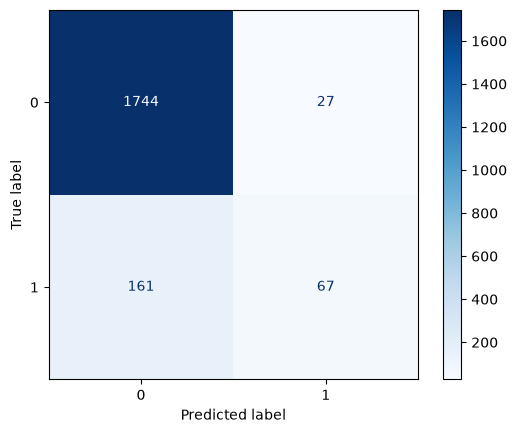

In [6]:
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=logreg.classes_)
disp.plot(cmap="Blues")
plt.show()

The confusion matrix is often the best starting point because it shows exactly which kind of error the model is making. From here, we can compute more specialized metrics depending on the use case.


## Accuracy


Accuracy is the fraction of predictions that are correct overall.

$$Accuracy = \frac{TP + TN}{TP + TN + FP + FN}$$

It is easy to understand, but it can be misleading when the classes are imbalanced.


In [7]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.3f}")

Accuracy: 0.906


A high accuracy does not necessarily mean the model is doing a good job on the minority class. If missing positive cases is expensive, accuracy alone is usually not the right metric to optimize.


## Recall


Recall measures how many of the actual positive cases the model successfully finds.

$$Recall = \frac{TP}{TP + FN}$$

Recall is especially important when false negatives are costly, for example in fraud detection or medical screening.


In [8]:
recall = recall_score(y_test, y_pred)
print(f"Recall: {recall:.3f}")

Recall: 0.294


Our recall is quite low, which means the model misses a substantial share of the actually safe samples. This is common when the positive class is rare and the default decision threshold stays at `0.5`.


## Precision


Precision measures how many predicted positive cases are actually positive.

$$Precision = \frac{TP}{TP + FP}$$

Precision matters when false positives are expensive, for example when flagging legitimate transactions as fraud.


In [9]:
precision = precision_score(y_test, y_pred)
print(f"Precision: {precision:.3f}")

Precision: 0.713


In this example, precision is much higher than recall. That tells us the model is fairly cautious about predicting the positive class: when it predicts `safe`, it is often right, but it misses many truly safe samples.


## Threshold Trade-off


Precision and recall are closely tied to the classification threshold. Changing the threshold changes how many samples are labeled positive.

```mermaid
flowchart LR
    A[Lower decision threshold] --> B[More predicted positives]
    B --> C[Recall often increases]
    B --> D[Precision may decrease]
```

This trade-off is one reason why looking at several metrics together is more informative than relying on only one.


## F1 Score


The F1 score combines precision and recall into a single number by taking their harmonic mean.

$$F1 = 2 * \frac{Precision * Recall}{Precision + Recall}$$

It is useful when you want a balance between false positives and false negatives and when class imbalance makes accuracy less informative.


In [10]:
f1 = f1_score(y_test, y_pred)
print(f"F1 score: {f1:.3f}")

F1 score: 0.416


Because F1 depends on both precision and recall, it only becomes strong when both of them are reasonably strong. A low F1 score usually indicates that at least one side of the trade-off is weak.


## ROC Curve and ROC-AUC


The metrics above use predicted class labels. ROC analysis is different: it uses predicted probabilities and evaluates model behavior across many possible thresholds.

- `TPR` is the true positive rate, which is the same as recall.
- `FPR` is the false positive rate, computed as $FP / (FP + TN)$.


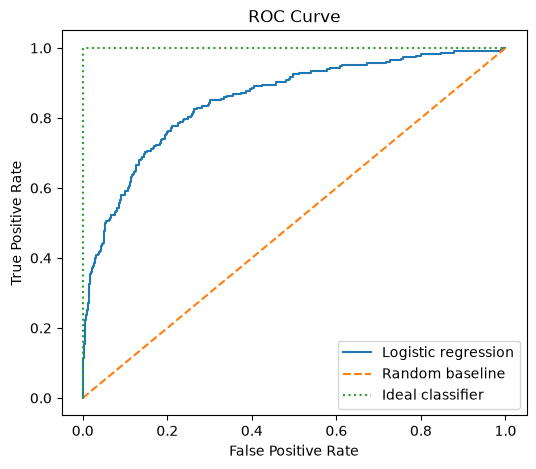

In [11]:
fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label="Logistic regression")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random baseline")
plt.plot([0, 0, 1], [0, 1, 1], linestyle=":", label="Ideal classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [12]:
auc = roc_auc_score(y_test, y_pred_proba)
print(f"ROC-AUC: {auc:.3f}")

ROC-AUC: 0.852


ROC-AUC summarizes the ROC curve into a single number.

- `0.5` means the model is no better than random guessing.
- `1.0` means perfect ranking of positives above negatives.

Our AUC is clearly above `0.5`, so the model has learned useful signal even though the default threshold still leads to weak recall.


## Precision-Recall Curve

On imbalanced datasets, a precision-recall curve is often more informative than ROC analysis because it focuses directly on the trade-off between finding positive cases and avoiding false alarms.

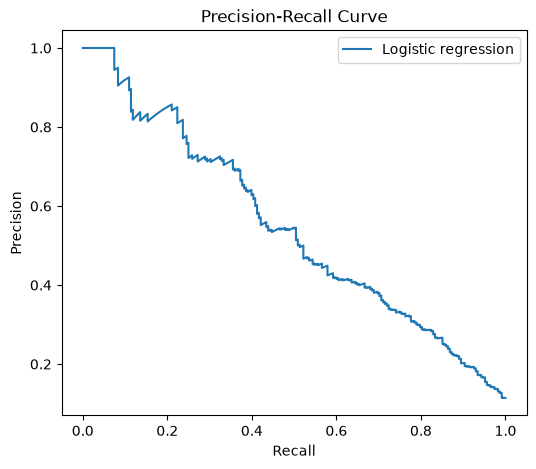

Average precision: 0.546


In [13]:
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test, y_pred_proba)
average_precision = average_precision_score(y_test, y_pred_proba)

plt.figure(figsize=(6, 5))
plt.plot(pr_recall, pr_precision, label="Logistic regression")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()
plt.show()

print(f"Average precision: {average_precision:.3f}")

## Metric Summary


In [14]:
pd.DataFrame(
    {
        "metric": ["accuracy", "recall", "precision", "f1", "roc_auc"],
        "value": [accuracy, recall, precision, f1, auc],
    }
).round(3)

,metric,value
0,accuracy,0.906
1,recall,0.294
2,precision,0.713
3,f1,0.416
4,roc_auc,0.852


A simple rule of thumb for choosing a metric is:

```mermaid
flowchart TD
    A[What matters most?] --> B[Missing positives is costly]
    A --> C[False alarms are costly]
    A --> D[Need one balanced metric]
    A --> E[Need threshold-independent ranking]
    B --> F[Focus on recall]
    C --> G[Focus on precision]
    D --> H[Focus on F1 score]
    E --> I[Focus on ROC-AUC]
```


## Conclusion

There is no universally best classification metric. The right metric depends on the business problem, the class balance, and which kind of mistake matters most.

In practice, it is a good idea to start with the confusion matrix, then compare the specific metrics that align with your real-world cost of errors.
